# df_analysis.csv 반도체 공정 데이터 분석

1. 데이터 로드 및 기본 점검
2. 라벨(Defect / 두께정상 / CD정상) 정의 확인
3. 변수 정리 (상수·중복 제거)
4. 단변량 관계 분석 (상관, 그룹 비교)
5. Target 회귀 모델 & 변수 중요도
6. Defect 분류 모델 (Target 제외)
7. 해석 가능한 규칙 추출 (Decision Tree, Partial Dependence)
8. 고위험 공정 조건 & 시각화

## 1. 데이터 로드 및 기본 점검
파일은 CP949 인코딩입니다.

In [1]:
import warnings
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

df = pd.read_csv('../data/df_analysis.csv', encoding='cp949')
print(f'데이터 크기: {df.shape[0]:,}행 × {df.shape[1]}열')
df.head()

데이터 크기: 1,664행 × 45열


,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,resist_target,N2_HMDS,pressure_HMDS,temp_HMDS,temp_HMDS_bake,time_HMDS_bake,spin1,spin2,spin3,photoresist_bake,temp_softbake,time_softbake,Line_CD,UV_type,Wavelength,Resolution,Energy_Exposure,Thin F4,Thin F3,Thin F2,Thin F1,Temp_Etching,Source_Power,Selectivity,Flux60s,Flux90s,Flux160s,Flux480s,Flux840s,input_Energy,Temp_implantation,Furance_Temp,RTA_Temp,Target,Temp_Oxid,Defect,두께정상,CD정상
0,dry,1214.310,O2,26.69,0.203,120,713.132,1.46994,17.367,15.006,20.001,200.551,90.001,502.391,4017.144,4903.611,5.020,91.918,30.005,41.676,I,365,505.388,109.628,340,1522.0,3644,5732.0,72.651,52.103,1.030,1.500000e+16,1.320000e+17,6.470000e+17,3.010000e+17,6.000000e+17,30795.934,103.433,854,154,141,866.337,0,정상,정상
1,dry,978.111,O2,30.86,0.217,137,714.295,0.86579,16.090,15.059,19.993,199.835,89.999,507.183,4072.913,4979.082,4.937,90.976,30.005,53.612,H,405,541.732,104.917,265,1513.0,3631,5729.0,70.267,52.004,1.038,1.110000e+16,4.370000e+16,1.040000e+18,3.030000e+17,6.000000e+17,32135.618,105.552,895,156,55,866.337,0,정상,정상
2,dry,1176.020,O2,31.07,0.218,116,710.114,0.90483,19.026,14.930,19.995,202.118,90.001,501.286,4084.939,5031.989,4.888,91.969,30.006,47.598,I,365,532.200,106.632,411,1568.0,3653,5729.0,71.231,50.846,1.005,1.040000e+16,1.510000e+16,6.470000e+17,2.980000e+17,6.000000e+17,31057.895,102.598,898,152,96,866.337,0,정상,정상
3,dry,933.443,O2,31.04,0.196,143,710.617,0.42197,18.891,14.947,20.004,194.668,90.000,503.396,4045.078,4969.316,4.933,91.458,30.001,32.843,G,436,537.729,108.785,328,1326.0,3661,5718.0,71.295,51.665,1.025,8.890000e+15,1.020000e+17,3.410000e+17,3.000000e+17,6.000000e+17,32140.566,102.963,879,155,105,866.337,0,정상,정상
4,wet,1140.600,H2O,31.37,0.215,76,711.632,1.70139,13.788,14.820,19.998,202.192,90.000,501.423,4010.176,5092.407,5.050,94.723,29.988,57.370,H,405,522.143,109.913,219,1451.0,3637,5729.0,72.983,50.787,1.038,1.670000e+16,7.880000e+16,7.260000e+17,3.020000e+17,6.000000e+17,31986.009,101.419,882,155,79,866.337,0,정상,비정상


In [2]:
print(f'결측치 합계 : {df.isna().sum().sum():,}')
print(f'중복 행     : {df.duplicated().sum():,}')
print()
print(f'[컬럼 타입별 개수]')
print(df.dtypes.value_counts().to_string())
print()
print(f'[범주형 변수 분포]')
for c in ['type', 'Vapor', 'UV_type', '두께정상', 'CD정상']:
    vc = df[c].value_counts()
    detail = ', '.join(f'{k} {v:,}개 ({v / len(df):.1%})' for k, v in vc.items())
    print(f'  {c:<8s}: {detail}')

결측치 합계 : 0
중복 행     : 0

[컬럼 타입별 개수]
float64    32
int64       8
str         5

[범주형 변수 분포]
  type    : dry 970개 (58.3%), wet 694개 (41.7%)
  Vapor   : O2 970개 (58.3%), H2O 694개 (41.7%)
  UV_type : G 613개 (36.8%), H 554개 (33.3%), I 497개 (29.9%)
  두께정상    : 정상 1,515개 (91.0%), 비정상 149개 (9.0%)
  CD정상    : 정상 1,372개 (82.5%), 비정상 292개 (17.5%)


In [3]:
desc = df.describe().T
desc['count'] = desc['count'].astype(int)
desc['nunique'] = df.nunique()
desc['cv%'] = desc['std'] / desc['mean'] * 100

# 지수 표기 대신 천 단위 콤마 + 소수점 4자리 (count·nunique 는 정수)
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(desc)

,count,mean,std,min,25%,50%,75%,max,nunique,cv%
Temp_OXid,1664,"1,067.9252",150.1664,862.0110,888.4198,"1,071.6750","1,190.9800","1,311.2300",1616,14.0615
ppm,1664,33.3827,8.1218,21.0700,25.5300,33.6000,39.5100,49.9100,496,24.3295
Pressure,1664,0.2108,0.0092,0.1800,0.2040,0.2120,0.2170,0.2290,46,4.3842
Oxid_time,1664,99.0469,72.6014,8.0000,31.0000,86.0000,148.0000,291.0000,197,73.3001
thickness,1664,711.1780,7.8135,681.4350,707.0610,711.7125,715.5640,737.4020,825,1.0987
resist_target,1664,1.1920,0.4156,0.0544,0.8824,1.1138,1.4891,2.3943,830,34.8621
N2_HMDS,1664,16.0714,2.2415,9.4970,14.7037,16.3090,17.3670,23.5730,777,13.9473
pressure_HMDS,1664,15.0035,0.0778,14.7760,14.9510,15.0030,15.0560,15.2810,303,0.5185
temp_HMDS,1664,19.9995,0.0037,19.9860,19.9970,20.0000,20.0020,20.0120,26,0.0184
temp_HMDS_bake,1664,200.5409,2.8794,191.2090,198.3415,200.5390,202.7900,209.5210,801,1.4358


## 2. 라벨 정의 확인
- `Defect` 는 `Target` 임계값으로 결정되는지
- `두께정상` 은 `thickness`, `CD정상` 은 `Line_CD` 로 결정되는지

In [4]:
# Defect=0 의 Target 최대값 vs Defect=1 의 Target 최소값
df.groupby('Defect')['Target'].describe()

,count,mean,std,min,25%,50%,75%,max
Defect,,,,,,,,
0,1543.0,90.580039,41.009219,0.0,60.5,90.0,117.0,193.0
1,121.0,255.115702,79.973974,195.0,207.0,223.0,258.0,495.0


In [5]:
thk = df.groupby('두께정상')['thickness'].agg(['min', 'max', 'count'])
cd = df.groupby('CD정상')['Line_CD'].agg(['min', 'max', 'count'])
print(f'[두께정상 vs thickness]')
print(thk)
print()
print(f'[CD정상 vs Line_CD]')
print(cd)
print()
print(f'CD 비정상 내역: Line_CD < 22 → {(df.Line_CD < 22).sum()}개 / Line_CD > 55 → {(df.Line_CD > 55).sum()}개')

[두께정상 vs thickness]
          min      max  count
두께정상                         
비정상   681.435  699.922    149
정상    700.313  737.402   1515

[CD정상 vs Line_CD]
         min     max  count
CD정상                       
비정상    4.562  76.265    292
정상    22.161  54.979   1372

CD 비정상 내역: Line_CD < 22 → 72개 / Line_CD > 55 → 220개


**결론**
- `Defect = (Target >= 195)` → Defect 예측 모델에 Target을 넣으면 **leakage**
- `두께정상 = thickness >= 700`, `CD정상 = 22 <= Line_CD <= 55`

## 3. 변수 정리 (상수·1:1 중복 컬럼 확인)

In [6]:
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f'상수 컬럼: {const_cols}')
print()
print(f'[type × Vapor]')
print(pd.crosstab(df['type'], df['Vapor']))
print()
print(f'[UV_type × Wavelength]')
print(pd.crosstab(df['UV_type'], df['Wavelength']))

상수 컬럼: ['Flux840s', 'Temp_Oxid']

[type × Vapor]
Vapor  H2O   O2
type           
dry      0  970
wet    694    0

[UV_type × Wavelength]
Wavelength  365  405  436
UV_type                  
G             0    0  613
H             0  554    0
I           497    0    0


In [7]:
DROP = ['Target', 'Defect',            # 목표변수
        'Flux840s', 'Temp_Oxid',       # 상수
        'Vapor', 'Wavelength',         # type / UV_type 과 1:1 중복
        '두께정상', 'CD정상']           # thickness / Line_CD 에서 파생

X = df.drop(columns=DROP).copy()
X['type'] = (X['type'] == 'wet').astype(int)
X = pd.get_dummies(X, columns=['UV_type'], dtype=int).astype(float)
y = df['Target']
yd = df['Defect']
print(f'입력 X: {X.shape[0]:,}행 × {X.shape[1]}열 | Defect 비율: {yd.mean():.2%}')

입력 X: 1,664행 × 39열 | Defect 비율: 7.27%


## 4. 단변량 관계 분석

In [8]:
num = df.select_dtypes('number').drop(columns=['Flux840s', 'Temp_Oxid'])
corr = num.corr(method='spearman')[['Target', 'Defect']].drop(['Target', 'Defect'])
corr.reindex(corr['Target'].abs().sort_values(ascending=False).index).round(3).head(15)

,Target,Defect
Thin F2,0.573,0.265
Thin F4,0.571,0.266
Thin F3,0.424,0.194
Line_CD,0.197,0.115
Furance_Temp,-0.192,-0.028
resist_target,0.167,0.115
Selectivity,0.165,0.074
Source_Power,0.162,0.070
Energy_Exposure,0.150,0.048
temp_softbake,-0.144,-0.109


In [9]:
# 정상 vs 불량 그룹 간 차이 (Mann-Whitney U)
rows = []
for col in num.columns.drop(['Defect', 'Target']):
    a, b = num.loc[yd == 0, col], num.loc[yd == 1, col]
    rows.append((col, a.mean(), b.mean(), stats.mannwhitneyu(a, b).pvalue))
pd.DataFrame(rows, columns=['feature', 'mean_정상', 'mean_불량', 'p_value']).sort_values('p_value').head(12)

,feature,mean_정상,mean_불량,p_value
21,Thin F4,2.853876e+02,4.341405e+02,2.348703e-27
23,Thin F2,3.650962e+03,3.669240e+03,3.989494e-27
22,Thin F3,1.464083e+03,1.534331e+03,2.505539e-15
2,Pressure,2.104504e-01,2.154215e-01,2.157416e-08
4,thickness,7.108844e+02,7.149222e+02,2.551956e-08
5,resist_target,1.177367e+00,1.379234e+00,2.635455e-06
17,Line_CD,4.032200e+01,4.562335e+01,2.835341e-06
0,Temp_OXid,1.072950e+03,1.003851e+03,8.166406e-06
15,temp_softbake,9.201579e+01,9.136177e+01,8.794754e-06
29,Flux90s,8.197383e+16,6.144608e+16,4.250933e-05


In [10]:
# 범주형 변수별 불량률 + 카이제곱 검정
for c in ['type', 'UV_type', '두께정상', 'CD정상']:
    t = df.groupby(c)['Defect'].agg(['mean', 'count'])
    p = stats.chi2_contingency(pd.crosstab(df[c], df['Defect']))[1]
    print(f'[{c}]  chi2 p-value = {p:.2e}')
    for k, (rate, n) in t.iterrows():
        print(f'  {k:<4s} 불량률 {rate:6.1%}  (n={n:,.0f})')
    print()

ct = pd.crosstab(df.type, df.UV_type, df.Defect, aggfunc='mean')
print(f'[type × UV_type 불량률]')
print(ct.map(lambda v: f'{v:.1%}'))

[type]  chi2 p-value = 5.97e-05


  dry  불량률   9.5%  (n=970)
  wet  불량률   4.2%  (n=694)

[UV_type]  chi2 p-value = 3.27e-02
  G    불량률   5.7%  (n=613)
  H    불량률   9.6%  (n=554)
  I    불량률   6.6%  (n=497)

[두께정상]  chi2 p-value = 5.85e-03
  비정상  불량률   1.3%  (n=149)
  정상   불량률   7.9%  (n=1,515)

[CD정상]  chi2 p-value = 5.17e-03
  비정상  불량률  11.3%  (n=292)
  정상   불량률   6.4%  (n=1,372)

[type × UV_type 불량률]
UV_type     G      H     I
type                      
dry      6.7%  14.9%  6.8%
wet      2.3%   1.8%  6.6%


In [11]:
# 주요 변수 5분위 구간별 불량률 / Target 평균
for c in ['Thin F2', 'Thin F4', 'Thin F3', 'Pressure']:
    g = df.groupby(pd.qcut(df[c], 5), observed=True).agg(
        defect_rate=('Defect', 'mean'), target_mean=('Target', 'mean'), n=('Defect', 'size'))
    print(f'[{c}] 5분위 구간별')
    print(g.round(3))
    print()

[Thin F2] 5분위 구간별
                    defect_rate  target_mean    n
Thin F2                                          
(3593.999, 3638.0]        0.000       57.897  360
(3638.0, 3645.0]          0.015       86.905  338
(3645.0, 3655.0]          0.060      102.811  302
(3655.0, 3667.0]          0.103      112.420  348
(3667.0, 3723.0]          0.196      159.006  316

[Thin F4] 5분위 구간별
                 defect_rate  target_mean    n
Thin F4                                       
(12.999, 187.0]        0.018       57.861  338
(187.0, 241.0]         0.027       86.796  329
(241.0, 315.0]         0.006      102.762  340
(315.0, 398.8]         0.120      120.960  324
(398.8, 687.0]         0.195      145.318  333

[Thin F3] 5분위 구간별
                    defect_rate  target_mean    n
Thin F3                                          
(1204.999, 1386.6]        0.021       68.829  333
(1386.6, 1441.0]          0.028       85.031  354
(1441.0, 1486.0]          0.048      103.272  313
(1486.0, 1548.0

## 5. Target 회귀 모델 & 변수 중요도

In [12]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

kf = KFold(5, shuffle=True, random_state=0)
reg_models = {
    'Ridge':        make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
    'RandomForest': RandomForestRegressor(500, min_samples_leaf=3, n_jobs=-1, random_state=0),
    'HistGB':       HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0),
}
for name, m in reg_models.items():
    r2 = cross_val_score(m, X, y, cv=kf, scoring='r2')
    mae = -cross_val_score(m, X, y, cv=kf, scoring='neg_mean_absolute_error')
    print(f'{name:13s} R2={r2.mean():.3f}±{r2.std():.3f}  MAE={mae.mean():.1f}')

Ridge         R2=0.554±0.046  MAE=28.8


RandomForest  R2=0.716±0.059  MAE=19.7


HistGB        R2=0.731±0.066  MAE=17.3


In [13]:
# Permutation importance (hold-out 25%)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)
hgb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(Xtr, ytr)
pi = permutation_importance(hgb, Xte, yte, n_repeats=15, random_state=0, scoring='r2')
imp = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False)
imp.head(12).round(4)

Thin F2            0.5545
Thin F4            0.3395
ppm                0.0812
Thin F3            0.0607
Temp_OXid          0.0264
Pressure           0.0262
Line_CD            0.0142
Temp_Etching       0.0103
Resolution         0.0102
thickness          0.0096
Energy_Exposure    0.0068
spin3              0.0065
dtype: float64

In [14]:
# Ridge 표준화 계수: 1 SD 증가 시 Target 변화량 (방향 확인용)
ridge = reg_models['Ridge'].fit(X, y)
pd.Series(ridge[-1].coef_, X.columns).sort_values(key=abs, ascending=False).head(12).round(2)

Thin F4          25.46
Thin F2          22.44
Thin F3          13.32
Pressure          9.82
Temp_OXid        -6.09
ppm              -4.97
Flux160s         -4.15
Thin F1          -3.87
Flux90s          -3.69
Line_CD           3.26
thickness         2.95
temp_softbake    -2.94
dtype: float64

## 6. Defect 분류 모델 (Target 제외)

In [15]:
skf = StratifiedKFold(5, shuffle=True, random_state=0)
clf_models = {
    'Logistic':     make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000)),
    'RandomForest': RandomForestClassifier(500, min_samples_leaf=3, class_weight='balanced', n_jobs=-1, random_state=0),
    'HistGB':       HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=0),
}
proba = {}
for name, m in clf_models.items():
    proba[name] = cross_val_predict(m, X, yd, cv=skf, method='predict_proba')[:, 1]
    print(f'{name:13s} ROC-AUC={roc_auc_score(yd, proba[name]):.3f}  '
          f'PR-AUC={average_precision_score(yd, proba[name]):.3f}  (base {yd.mean():.3f})')

Logistic      ROC-AUC=0.911  PR-AUC=0.529  (base 0.073)


RandomForest  ROC-AUC=0.983  PR-AUC=0.888  (base 0.073)


HistGB        ROC-AUC=0.979  PR-AUC=0.888  (base 0.073)


In [16]:
report = classification_report(yd, (proba['RandomForest'] > 0.5).astype(int), digits=3)
print(f'[RandomForest 분류 리포트 (threshold = 0.5)]')
print(report)

[RandomForest 분류 리포트 (threshold = 0.5)]
              precision    recall  f1-score   support

           0      0.982     0.990     0.986      1543
           1      0.861     0.769     0.812       121

    accuracy                          0.974      1664
   macro avg      0.922     0.879     0.899      1664
weighted avg      0.973     0.974     0.973      1664



## 7. 해석 가능한 규칙 추출

In [17]:
from sklearn.tree import DecisionTreeClassifier, export_text

for d in [2, 3, 4]:
    t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, class_weight='balanced', random_state=0)
    auc = cross_val_score(t, X, yd, cv=skf, scoring='roc_auc').mean()
    print(f'max_depth={d}  CV ROC-AUC = {auc:.3f}')

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0).fit(X, yd)
print()
print(f'[Decision Tree 규칙 (max_depth=3), weights = [정상, 불량]]')
print(export_text(tree, feature_names=list(X.columns), show_weights=True))

max_depth=2  CV ROC-AUC = 0.817


max_depth=3  CV ROC-AUC = 0.888

max_depth=4  CV ROC-AUC = 0.876

[Decision Tree 규칙 (max_depth=3), weights = [정상, 불량]]
|--- Thin F4 <= 458.00
|   |--- Flux90s <= 6925000114176.00
|   |   |--- weights: [13.00, 8.00] class: 0
|   |--- Flux90s >  6925000114176.00
|   |   |--- Thin F4 <= 324.50
|   |   |   |--- weights: [1030.00, 14.00] class: 0
|   |   |--- Thin F4 >  324.50
|   |   |   |--- weights: [368.00, 40.00] class: 0
|--- Thin F4 >  458.00
|   |--- ppm <= 28.45
|   |   |--- weights: [2.00, 22.00] class: 1
|   |--- ppm >  28.45
|   |   |--- Thin F2 <= 3656.50
|   |   |   |--- weights: [65.00, 2.00] class: 0
|   |   |--- Thin F2 >  3656.50
|   |   |   |--- weights: [65.00, 35.00] class: 0



In [18]:
# Partial dependence: 각 변수 값에 따른 Target 평균 변화 (HistGB 전체 학습)
hgb_full = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(X, y)
for f in ['Thin F2', 'Thin F4', 'Thin F3', 'ppm', 'Temp_OXid', 'Pressure']:
    r = partial_dependence(hgb_full, X, [f], grid_resolution=8)
    grid = ' '.join(f'{v:>9.4g}' for v in r['grid_values'][0])
    effect = ' '.join(f'{v:>+9.1f}' for v in r['average'][0])
    print(f'[{f}]')
    print(f'  변수 값    : {grid}')
    print(f'  Target 변화: {effect}')
    print()

[Thin F2]
  변수 값    :      3631      3638      3646      3653      3661      3668      3676      3683
  Target 변화:     -39.1     -28.4      -6.8      +0.8      +4.9     +22.5     +41.7     +54.3

[Thin F4]
  변수 값    :       137     190.9     244.8     298.7     352.7     406.6     460.5     514.4
  Target 변화:     -32.2     -22.2      -8.1      +3.5     +11.6     +15.8     +31.6     +37.8

[Thin F3]
  변수 값    :      1323      1369      1414      1460      1506      1552      1597      1643
  Target 변화:     -11.3     -10.7      -7.2      -0.1      +3.3      +9.8     +12.1     +17.1

[ppm]
  변수 값    :     22.12     25.41      28.7     31.99     35.29     38.58     41.87     45.16
  Target 변화:     +18.3      -1.5      -2.7      -2.5      -2.7      -0.5      -0.0      -1.0

[Temp_OXid]
  변수 값    :     871.9     931.2     990.6      1050      1109      1169      1228      1287
  Target 변화:     +18.5      +0.9      -0.8      -2.4      -2.0      -3.1      -2.6      -4.1

[Pressure]
  변수 값    :

In [19]:
# 산화온도 900°C 미만 구간 확인
df['lowT'] = df['Temp_OXid'] < 900
df['F4_hi'] = df['Thin F4'] > 458
by_type = df.groupby(['type', 'lowT']).agg(n=('Defect', 'size'), defect=('Defect', 'mean')).round(3)
by_f4 = df.groupby(['lowT', 'F4_hi']).agg(n=('Defect', 'size'), defect=('Defect', 'mean')).round(3)
print(f'[type × 산화온도<900]')
print(by_type)
print()
print(f'[산화온도<900 × Thin F4>458]')
print(by_f4)
print()

# Flux90s 비정상 저값 웨이퍼
low_flux = df['Flux90s'] < 6.9e12
print(f'Flux90s 비정상 저값(< 6.9e12): {low_flux.sum()}개, 불량률 {df.loc[low_flux, "Defect"].mean():.1%}')

[type × 산화온도<900]
              n  defect
type lowT              
dry  False  512   0.066
     True   458   0.127
wet  False  693   0.042
     True     1   0.000

[산화온도<900 × Thin F4>458]
                n  defect
lowT  F4_hi              
False False  1029   0.018
      True    176   0.250
True  False   444   0.097
      True     15   1.000

Flux90s 비정상 저값(< 6.9e12): 23개, 불량률 43.5%


## 8. 고위험 공정 조건 & 시각화

In [20]:
segment = pd.Series(np.select(
    [df.lowT & df.F4_hi,
     df.F4_hi & (df.ppm <= 28.45),
     df.F4_hi,
     df.lowT],
    ['산화온도<900 & F4>458', 'F4>458 & ppm≤28.45', 'F4>458 (그 외)', '산화온도<900 (F4≤458)'],
    '기타 (기준)'), index=df.index)
seg_table = df.groupby(segment)['Defect'].agg(불량률='mean', n='size').sort_values('불량률', ascending=False)
seg_table

,불량률,n
산화온도<900 & F4>458,1.000000,15
F4>458 & ppm≤28.45,0.833333,12
F4>458 (그 외),0.207317,164
산화온도<900 (F4≤458),0.096847,444
기타 (기준),0.018465,1029


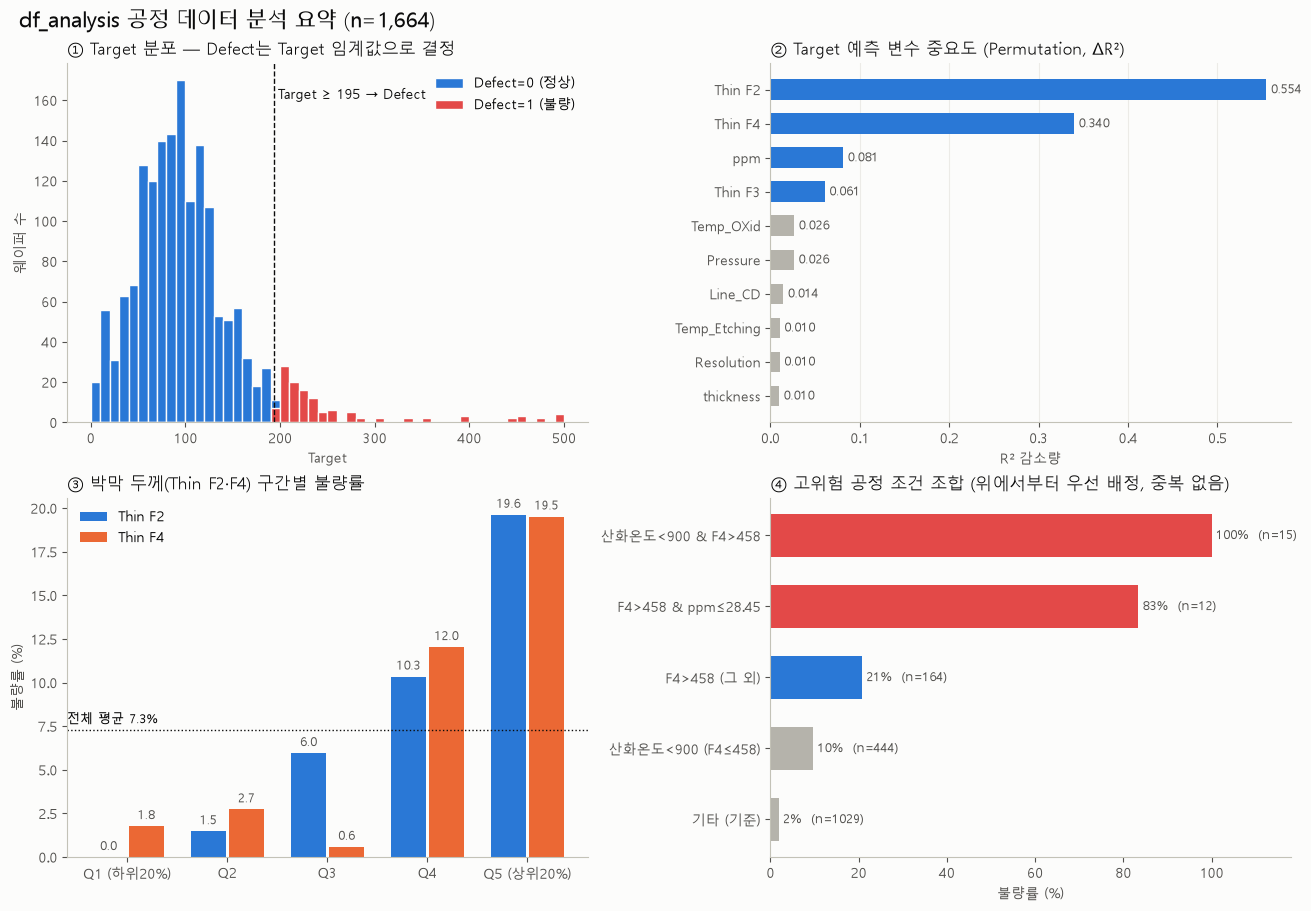

In [21]:
import os
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
BLUE, ORANGE, RED, GRAY, INK = '#2a78d6', '#eb6834', '#e34948', '#b5b3ab', '#0b0b0b'

fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle('df_analysis 공정 데이터 분석 요약 (n=1,664)', fontsize=15, color=INK, x=0.01, ha='left')

# ① Target 분포
a = ax[0, 0]; bins = np.arange(0, 505, 10)
a.hist(df.loc[yd == 0, 'Target'], bins=bins, color=BLUE, edgecolor='#fcfcfb', label='Defect=0 (정상)')
a.hist(df.loc[yd == 1, 'Target'], bins=bins, color=RED, edgecolor='#fcfcfb', label='Defect=1 (불량)')
a.axvline(194, color=INK, lw=1, ls='--')
a.text(198, a.get_ylim()[1] * .9, 'Target ≥ 195 → Defect', color=INK)
a.set_title('① Target 분포 — Defect는 Target 임계값으로 결정', loc='left', color=INK)
a.set_xlabel('Target'); a.set_ylabel('웨이퍼 수'); a.legend(frameon=False)

# ② 변수 중요도
a = ax[0, 1]; top = imp.head(10)[::-1]
a.barh(top.index, top.values, color=[BLUE if v > 0.05 else GRAY for v in top.values], height=0.6)
for i, v in enumerate(top.values):
    a.text(v + 0.005, i, f'{v:.3f}', va='center', color='#52514e', fontsize=9)
a.set_title('② Target 예측 변수 중요도 (Permutation, ΔR²)', loc='left', color=INK)
a.set_xlabel('R² 감소량'); a.grid(axis='x', color='#ecebe7'); a.set_axisbelow(True)

# ③ Thin F2 / F4 5분위 불량률
a = ax[1, 0]; w = 0.38; x = np.arange(5)
for k, (c, col) in enumerate([('Thin F2', BLUE), ('Thin F4', ORANGE)]):
    r = df.groupby(pd.qcut(df[c], 5), observed=True)['Defect'].mean() * 100
    a.bar(x + (k - .5) * w, r.values, w - 0.03, color=col, label=c)
    for xi, v in zip(x + (k - .5) * w, r.values):
        a.text(xi, v + .4, f'{v:.1f}', ha='center', fontsize=8.5, color='#52514e')
a.axhline(yd.mean() * 100, color=INK, lw=1, ls=':')
a.text(-0.6, yd.mean() * 100 + .4, '전체 평균 7.3%', ha='left', fontsize=9)
a.set_xticks(x, ['Q1 (하위20%)', 'Q2', 'Q3', 'Q4', 'Q5 (상위20%)'])
a.set_title('③ 박막 두께(Thin F2·F4) 구간별 불량률', loc='left', color=INK)
a.set_ylabel('불량률 (%)'); a.legend(frameon=False)

# ④ 고위험 조건 조합
a = ax[1, 1]; g = seg_table.sort_values('불량률')
a.barh(g.index, g['불량률'] * 100, height=0.6,
       color=[RED if m > .5 else (BLUE if m > .1 else GRAY) for m in g['불량률']])
for i, (m, n) in enumerate(zip(g['불량률'], g['n'])):
    a.text(m * 100 + 1, i, f'{m*100:.0f}%  (n={n})', va='center', fontsize=9, color='#52514e')
a.set_xlim(0, 118); a.set_xlabel('불량률 (%)')
a.set_title('④ 고위험 공정 조건 조합 (위에서부터 우선 배정, 중복 없음)', loc='left', color=INK)

os.makedirs('output', exist_ok=True)
fig.savefig('output/analysis_summary.png', dpi=150)
plt.show()

## 결론 요약
- `Defect = Target ≥ 195` (파생 라벨) / `두께정상 = thickness ≥ 700` / `CD정상 = 22 ≤ Line_CD ≤ 55`
- Target 예측: HistGB R² ≈ 0.73 · Defect 분류(Target 제외): RandomForest ROC-AUC ≈ 0.98
- 핵심 인자: **Thin F2, Thin F4** ≫ ppm, Thin F3, Temp_OXid, Pressure
- 고위험 조건: **산화온도 < 900°C & Thin F4 > 458 → 불량률 100% (15/15)**, Thin F4 > 458 & ppm ≤ 28.45 → 83%
- Dry 산화 불량률(9.5%)이 Wet(4.2%)의 2배 이상, Flux90s 비정상 저값 웨이퍼 불량률 43%
- 관측 데이터 기반 상관관계이므로 인과 확정은 DOE 검증 필요